# Seoul Bike-Sharing Demand Prediction
### Supervised Machine Learning Project (Finals)

**Dataset:** `SeoulBikeData-1.csv` — hourly bike-rental counts for the Seoul Metropolitan public bike system
**Task:** Binary classification — predict whether hourly bike demand is **High** or **Low**

---

## A. Introduction

### What the problem is about

The Seoul Metropolitan Government operates a public bike-sharing system (SeoulBike). This
dataset records, **hour by hour for a full year (1 Dec 2017 – 30 Nov 2018)**, how many bikes
were rented together with the weather and calendar conditions at that time: temperature,
humidity, wind speed, visibility, dew point, solar radiation, rainfall, snowfall, the season,
whether it is a holiday, and whether it is a functioning (working) day.

Understanding and **forecasting bike demand** is a practical operations problem: the city can
use a demand model to (i) place more bikes at stations before peak hours, (ii) schedule
maintenance on low-demand hours, and (iii) plan capacity for weather-driven swings.

### What this project produces

Rather than predicting the exact rental count (regression), this project casts the problem as a
**supervised binary classification** task, which the assignment requires to be evaluated with a
**confusion matrix**:

> **Given the weather and calendar conditions for a given hour, will bike demand be HIGH or LOW?**

* **Target (label):** `high_demand` — `1` (High) if the hourly rental count is at or above the
  dataset median, otherwise `0` (Low). Using the median produces a balanced, interpretable
  split ("above-average demand").
* **Input features:** weather measurements plus calendar features, some of which are engineered
  from the date (day of week, weekend flag) and one-hot encoded (season, holiday, functioning day).

The final deliverable of this notebook is a trained **Logistic Regression** classifier, an 80/20
train/test evaluation, a **confusion matrix**, and a comparison against a majority-class baseline —
all reproducible with a fixed random seed.

**Project structure**

| Section | Purpose |
|---|---|
| B | Data collection & preprocessing (EDA, cleaning) |
| C | Feature engineering & selection (correlation analysis) |
| D | Data splitting (80/20, `random_state=42`) |
| E | Model selection & training (Logistic Regression) |
| F | Model evaluation (confusion matrix, baseline, limitations) |

## 1. Import Libraries

All required libraries are imported here. `matplotlib` is set to the *inline* backend so that
every plot is rendered directly inside the notebook when it is executed.

In [27]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

%matplotlib inline

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Data Collection and Preprocessing

### 2.1 Data Collection

The data is loaded from `SeoulBikeData-1.csv`. Two collection details matter:

1. **Encoding** — the file is saved in **CP949** (the Windows Korean code page). Reading it with
   the default UTF-8 fails, so the encoding is set explicitly.
2. **Header text** — some column names contain the non-ASCII degree symbol, which reads back as
   a garbled character. These are normalised to clean, ASCII names during preprocessing
   (Section 2.3).

In [28]:
# The file is encoded in CP949 (Windows Korean), so we must specify the encoding.
raw = pd.read_csv("SeoulBikeData-1.csv", encoding="cp949")

print("Loaded", raw.shape[0], "rows and", raw.shape[1], "columns.\n")
print("Original column names (as read from the file):")
for c in raw.columns:
    print("   -", repr(c))
print("\nFirst 5 rows:")
raw.head()

Loaded 8760 rows and 14 columns.

Original column names (as read from the file):
   - 'Date'
   - 'Rented Bike Count'
   - 'Hour'
   - 'Temperature(캜)'
   - 'Humidity(%)'
   - 'Wind speed (m/s)'
   - 'Visibility (10m)'
   - 'Dew point temperature(캜)'
   - 'Solar Radiation (MJ/m2)'
   - 'Rainfall(mm)'
   - 'Snowfall (cm)'
   - 'Seasons'
   - 'Holiday'
   - 'Functioning Day'

First 5 rows:


,Date,Rented Bike Count,Hour,Temperature(캜),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(캜),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### 2.2 Exploratory Data Analysis (EDA)

We inspect the shape, data types, missing values and basic statistics before touching the
model. This tells us whether the data is usable and what cleaning is needed.

In [29]:
print("DATASET SIZE (rows, columns):", raw.shape)

print("\nMISSING VALUES PER COLUMN (total =", int(raw.isnull().sum().sum()), "):")
print(raw.isnull().sum().to_string())

print("\nDATA TYPES:")
print(raw.dtypes.to_string())

print("\nDESCRIPTIVE STATISTICS (numeric columns):")
raw.describe().to_string()

DATASET SIZE (rows, columns): (8760, 14)

MISSING VALUES PER COLUMN (total = 0 ):
Date                        0
Rented Bike Count           0
Hour                        0
Temperature(캜)              0
Humidity(%)                 0
Wind speed (m/s)            0
Visibility (10m)            0
Dew point temperature(캜)    0
Solar Radiation (MJ/m2)     0
Rainfall(mm)                0
Snowfall (cm)               0
Seasons                     0
Holiday                     0
Functioning Day             0

DATA TYPES:
Date                            str
Rented Bike Count             int64
Hour                          int64
Temperature(캜)              float64
Humidity(%)                   int64
Wind speed (m/s)            float64
Visibility (10m)              int64
Dew point temperature(캜)    float64
Solar Radiation (MJ/m2)     float64
Rainfall(mm)                float64
Snowfall (cm)               float64
Seasons                         str
Holiday                         str
Functioning Day  

'       Rented Bike Count         Hour  Temperature(캜)  Humidity(%)  Wind speed (m/s)  Visibility (10m)  Dew point temperature(캜)  Solar Radiation (MJ/m2)  Rainfall(mm)  Snowfall (cm)\ncount        8760.000000  8760.000000     8760.000000  8760.000000       8760.000000       8760.000000               8760.000000              8760.000000   8760.000000    8760.000000\nmean          704.602055    11.500000       12.882922    58.226256          1.724909       1436.825799                  4.073813                 0.569111      0.148687       0.075068\nstd           644.997468     6.922582       11.944825    20.362413          1.036300        608.298712                 13.060369                 0.868746      1.128193       0.436746\nmin             0.000000     0.000000      -17.800000     0.000000          0.000000         27.000000                -30.600000                 0.000000      0.000000       0.000000\n25%           191.000000     5.750000        3.500000    42.000000          0.9

### 2.3 Visual Explorations

The four panels below show how demand behaves across the day, the year and the distribution of
raw rental counts.

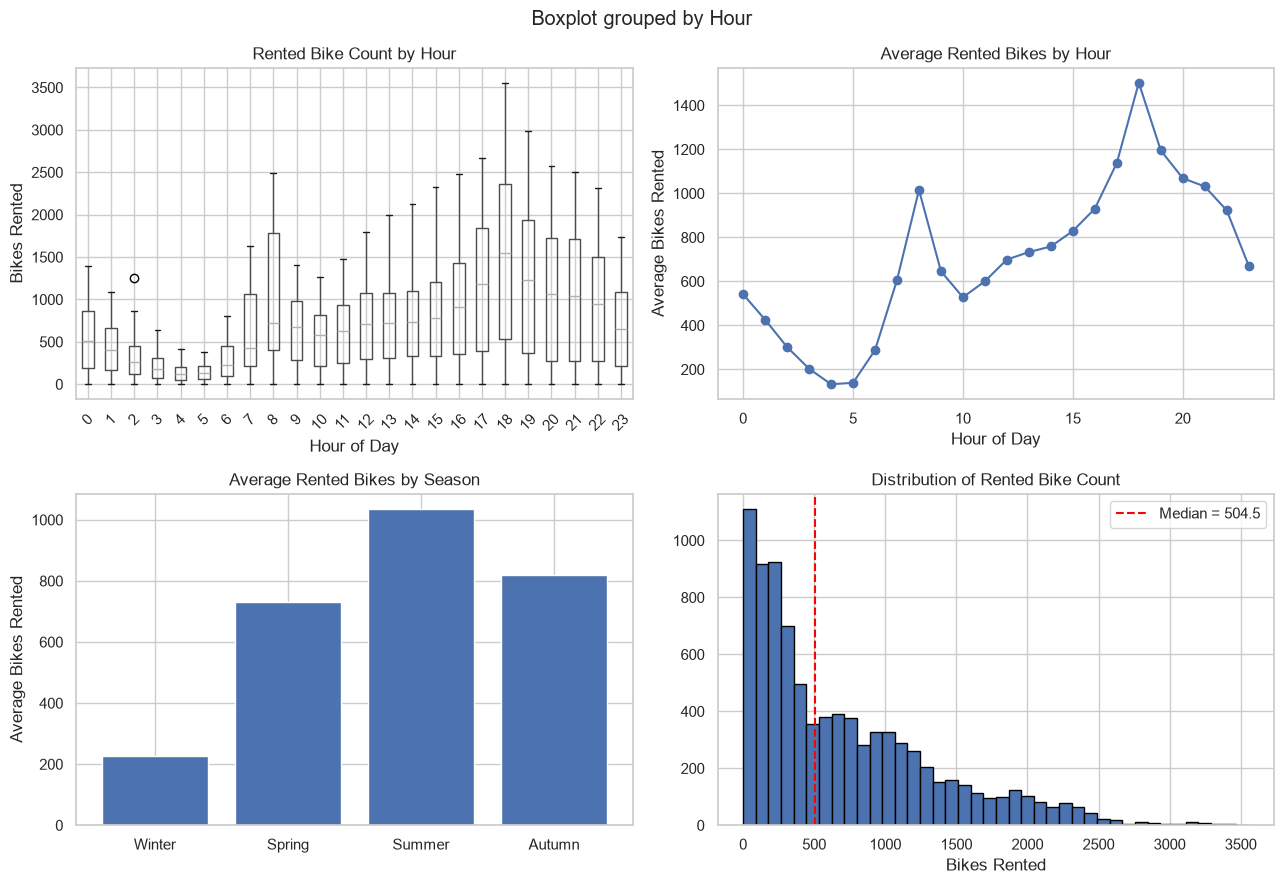

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Box plot of rented bike count per hour
raw.boxplot(column="Rented Bike Count", by="Hour", ax=axes[0, 0])
axes[0, 0].set_title("Rented Bike Count by Hour")
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Bikes Rented")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Mean rented bikes per hour
hourly = raw.groupby("Hour")["Rented Bike Count"].mean()
axes[0, 1].plot(hourly.index, hourly.values, marker="o")
axes[0, 1].set_title("Average Rented Bikes by Hour")
axes[0, 1].set_xlabel("Hour of Day")
axes[0, 1].set_ylabel("Average Bikes Rented")

# 3. Mean rented bikes per season
season = raw.groupby("Seasons")["Rented Bike Count"].mean()
season = season.reindex(["Winter", "Spring", "Summer", "Autumn"])
axes[1, 0].bar(season.index, season.values)
axes[1, 0].set_title("Average Rented Bikes by Season")
axes[1, 0].set_ylabel("Average Bikes Rented")

# 4. Distribution of rented bike count
axes[1, 1].hist(raw["Rented Bike Count"], bins=40, edgecolor="black")
med = raw["Rented Bike Count"].median()
axes[1, 1].axvline(med, color="red", linestyle="--", label=f"Median = {med:.1f}")
axes[1, 1].set_title("Distribution of Rented Bike Count")
axes[1, 1].set_xlabel("Bikes Rented")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**Interpretation of the EDA**

* **Strong daily (diurnal) cycle.** Demand is lowest in the small hours (~3–5 a.m.) and peaks at
  two commuting times: a **morning peak (~7–9 a.m.)** and a larger **evening peak (~17–19 h)**.
  `Hour` is therefore expected to be one of the most informative features.
* **Strong seasonal effect.** Summer has by far the highest average demand, while Winter is the
  lowest. `Season` / `Temperature` should be highly informative.
* **Right-skewed target.** The rental-count distribution is skewed right with a long tail to
  ~3,500 and a floor of 0. A single median cut therefore gives a clean, balanced binary target.
* **Clean data.** There are **no missing values** and **no duplicated rows**, so heavy cleaning is
  not required; the main preprocessing is *re-naming* the (partly non-ASCII) headers and
  *parsing the date*.


### 2.4 Data Cleaning & Preprocessing

Three cleaning/preparation steps are applied, each shown with its output:

1. **Rename columns** to clean ASCII names (matching on the text before the parenthesis, so the
   garbled degree symbol is never used directly).
2. **Parse the `Date` column** into a real datetime. The dates are **day-first**
   (`01/12/2017` = 1 December 2017), which the `Seasons` column confirms (Winter).
3. **Re-check data quality** (missing values, duplicates, date range).

In [31]:
# Work on a copy so the raw frame stays untouched
df = raw.copy()

# ---- Step 1: rename the (partly non-ASCII) headers to clean names ----
# We match on the ASCII text that precedes any parenthesis.
_NAME_MAP = {
    "Date": "date",
    "Rented Bike Count": "rented_bikes",
    "Hour": "hour",
    "Temperature": "temperature",
    "Humidity": "humidity",
    "Wind speed": "wind_speed",
    "Visibility": "visibility",
    "Dew point temperature": "dew_point",
    "Solar Radiation": "solar_radiation",
    "Rainfall": "rainfall",
    "Snowfall": "snowfall",
    "Seasons": "season",
    "Holiday": "holiday",
    "Functioning Day": "functioning_day",
}

def _clean_name(col):
    base = col.split("(")[0].strip()
    return _NAME_MAP.get(base, col)

df = df.rename(columns={c: _clean_name(c) for c in df.columns})
print("Columns after renaming:")
print(list(df.columns))

# ---- Step 2: parse the date (day-first) ----
df["date"] = pd.to_datetime(df["date"], dayfirst=True)

# ---- Step 3: re-check data quality ----
print("\nRows / Columns:", df.shape)
print("Remaining missing values:", int(df.isnull().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("\nData types after cleaning:")
print(df.dtypes.to_string())

Columns after renaming:
['date', 'rented_bikes', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point', 'solar_radiation', 'rainfall', 'snowfall', 'season', 'holiday', 'functioning_day']

Rows / Columns: (8760, 14)
Remaining missing values: 0
Duplicated rows: 0
Date range: 2017-12-01 to 2018-11-30

Data types after cleaning:
date               datetime64[us]
rented_bikes                int64
hour                        int64
temperature               float64
humidity                    int64
wind_speed                float64
visibility                  int64
dew_point                 float64
solar_radiation           float64
rainfall                  float64
snowfall                  float64
season                        str
holiday                       str
functioning_day               str


## 3. Feature Engineering

We build three groups of derived features:

1. **Time features from the date** — `day_of_week` (0 = Monday … 6 = Sunday) and a `weekend`
   flag (1 for Sat/Sun). Bike use on weekends differs from weekdays, so this adds signal the raw
   `Date` string does not expose.
2. **Binary encodings** of the two categorical columns: `holiday` (No Holiday = 0, Holiday = 1)
   and `functioning_day` (Yes = 1, No = 0).
3. **One-hot encoding** of `season` (drop-first to avoid the dummy-variable / collinearity
   problem), producing `season_Spring`, `season_Summer`, `season_Winter` (Autumn is the reference).

In [32]:
# ---- Time features derived from the parsed date ----
df["day_of_week"] = df["date"].dt.dayofweek           # 0 = Mon ... 6 = Sun
df["weekend"] = (df["day_of_week"] >= 5).astype(int)  # 1 = Sat/Sun

# ---- Encode the two binary categorical columns ----
df["holiday"] = df["holiday"].map({"No Holiday": 0, "Holiday": 1})
df["functioning_day"] = df["functioning_day"].map({"Yes": 1, "No": 0})

# ---- One-hot encode the season (drop first level) ----
season_dummies = pd.get_dummies(df["season"], prefix="season",
                                drop_first=True, dtype=int)
df = pd.concat([df, season_dummies], axis=1)
df = df.drop(columns=["season"])   # the original string column is now redundant

print("Columns after feature engineering:")
print(list(df.columns))
print("\nHead of the engineered frame:")
df.head()

Columns after feature engineering:
['date', 'rented_bikes', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point', 'solar_radiation', 'rainfall', 'snowfall', 'holiday', 'functioning_day', 'day_of_week', 'weekend', 'season_Spring', 'season_Summer', 'season_Winter']

Head of the engineered frame:


,date,rented_bikes,hour,temperature,humidity,wind_speed,visibility,dew_point,solar_radiation,rainfall,snowfall,holiday,functioning_day,day_of_week,weekend,season_Spring,season_Summer,season_Winter
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,0,1,4,0,0,0,1
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,0,1,4,0,0,0,1
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,0,1,4,0,0,0,1
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,0,1,4,0,0,0,1
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,0,1,4,0,0,0,1


### 3.1 Feature Selection — Correlation Analysis

Feature selection is justified with **correlation analysis** (Pearson correlation of each feature
with the raw rental count) plus a full correlation heatmap to check for redundant features.

* Features with a strong relationship to demand (`temperature`, `hour`, `dew_point`,
  `solar_radiation`) are clearly the most informative.
* `humidity`, `rainfall` and `snowfall` show a **negative** correlation — wetter/colder conditions
  suppress demand, which is a sensible, keep-the-feature signal.
* The engineered time/calendar features (`weekend`, `day_of_week`, `holiday`) capture behaviour
  that the raw `hour` alone does not.

All 16 engineered features are retained: none is a pure duplicate of another (the heatmap shows no
near-perfect pairs), and each has a plausible physical or behavioural reason to matter.

Correlation of each feature with 'rented_bikes' (sorted by |r|):
temperature        0.539
season_Winter     -0.425
hour               0.410
dew_point          0.380
season_Summer      0.297
solar_radiation    0.262
functioning_day    0.204
humidity          -0.200
visibility         0.199
snowfall          -0.142
rainfall          -0.123
wind_speed         0.121
holiday           -0.072
weekend           -0.036
day_of_week       -0.029
season_Spring      0.023


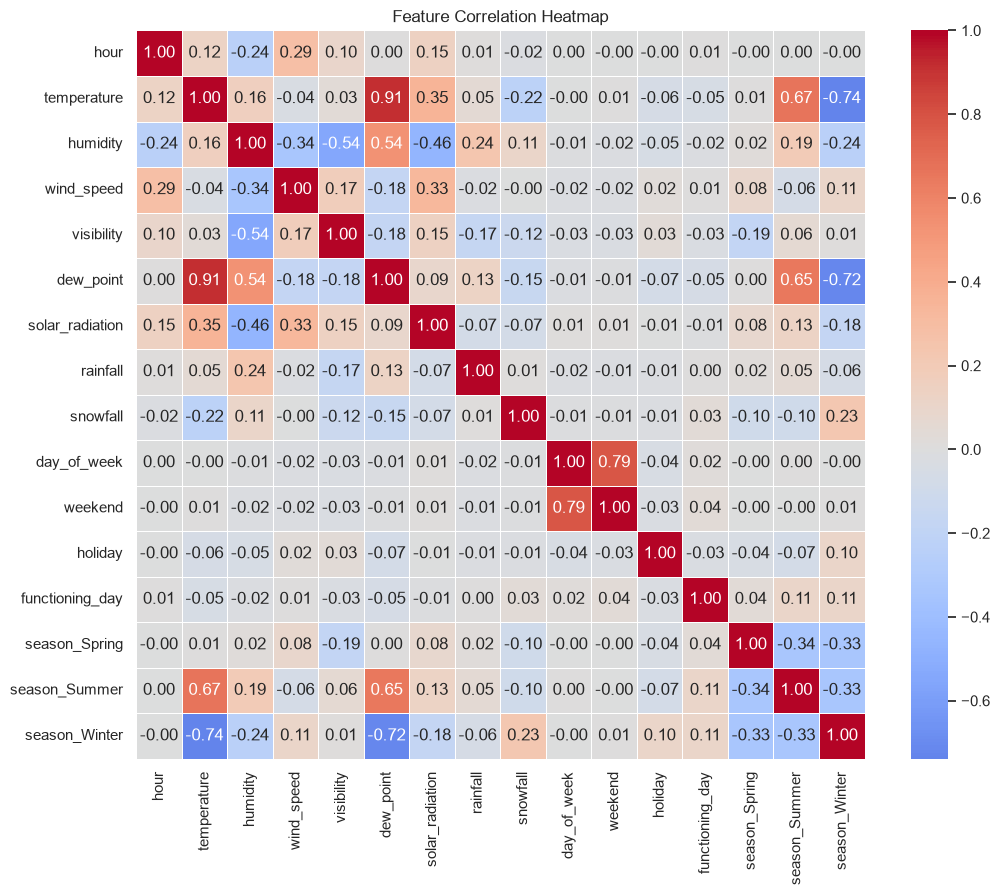

In [33]:
# The feature matrix used for modelling (numeric + encoded columns only)
feature_cols = [
    "hour", "temperature", "humidity", "wind_speed", "visibility",
    "dew_point", "solar_radiation", "rainfall", "snowfall",
    "day_of_week", "weekend", "holiday", "functioning_day",
    "season_Spring", "season_Summer", "season_Winter",
]

# Correlation of each feature with the raw rental count, sorted by strength
corr = df[feature_cols + ["rented_bikes"]].corr()["rented_bikes"].drop("rented_bikes")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
print("Correlation of each feature with 'rented_bikes' (sorted by |r|):")
print(corr.round(3).to_string())

# Correlation heatmap between features
plt.figure(figsize=(11, 9))
sns.heatmap(df[feature_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### 3.2 Defining the Classification Target

We convert the continuous `rented_bikes` count into a binary label `high_demand` using the
**dataset median** as the threshold. The median is a natural, interpretable cut ("above-average
demand") and it yields a well-balanced class distribution, which is ideal for reading a confusion
matrix.

> Note on leakage: this threshold is part of the **definition of the target**, not a fitted model
> parameter, so it is computed on the full data. It does **not** leak test information into the
> preprocessing of the *features* (the scaler is fit on the training set only — see Section 5).

In [34]:
median_bikes = df["rented_bikes"].median()
df["high_demand"] = (df["rented_bikes"] >= median_bikes).astype(int)

print("Demand threshold (median bikes/hour):", median_bikes)
print("\nClass balance:")
print(df["high_demand"].value_counts().rename_axis("label").to_string())
print("\nLabel meaning: 1 = High demand (>= median), 0 = Low demand (< median)")

Demand threshold (median bikes/hour): 504.5

Class balance:
label
0    4380
1    4380

Label meaning: 1 = High demand (>= median), 0 = Low demand (< median)


## 4. Data Splitting

The data is split **80% training / 20% testing** with **`random_state = 42`**, exactly as the
assignment requires. `stratify = y` is added so that both the training and testing sets preserve
the original 50/50 class balance (this does not change the split ratio or the seed).

In [35]:
# Separate features (X) and target (y)
X = df[feature_cols]
y = df["high_demand"]

# 80% train / 20% test, random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set  shape:", X_test.shape)
print("\nTraining class balance:\n", y_train.value_counts().to_string())
print("\nTesting class balance:\n", y_test.value_counts().to_string())

Training set shape: (7008, 16)
Testing set  shape: (1752, 16)

Training class balance:
 high_demand
1    3504
0    3504

Testing class balance:
 high_demand
1    876
0    876


## 5. Model Selection and Training

### Why Logistic Regression?

The assignment asks for a *simple* model, so **Logistic Regression** is the right choice:

* It is a standard, interpretable **linear** classifier — the model outputs a probability that an
  hour is High-demand, and we threshold at 0.5.
* It is a good **baseline workhorse** for tabular, moderate-size data and is fast to train and
  debug.
* Its **coefficients are directly interpretable** (direction and relative strength of each
  feature), which helps us *explain* the model — a learning outcome of this project.
* Because it assumes roughly linear, additive effects, it is an honest "simple" model: if it
  performs well, the result is not the product of an over-powerful black box.

The model uses `random_state = 42` and `max_iter = 1000` (to guarantee convergence of the
liblinear solver).

**No data leakage:** the features are standardised with a `StandardScaler` that is **fit on the
training set only** and then used to *transform* the test set. The test set never influences the
scaling statistics.

In [36]:
# Scale features using statistics from the TRAINING set only,
# then apply the same transform to the test set (no data leakage).
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the logistic-regression classifier
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model trained: LogisticRegression(max_iter=1000, random_state=42)")
print("\nLearned coefficients (features ranked by |coefficient|):")
coef = pd.Series(model.coef_[0], index=feature_cols)
coef = coef.reindex(coef.abs().sort_values(ascending=False).index)
print(coef.round(3).to_string())
print("\n(A positive coefficient pushes toward HIGH demand, negative toward LOW demand.)")

Model trained: LogisticRegression(max_iter=1000, random_state=42)

Learned coefficients (features ranked by |coefficient|):
functioning_day    1.845
season_Winter     -1.653
rainfall          -1.278
temperature        0.962
humidity          -0.918
hour               0.906
solar_radiation    0.644
season_Spring     -0.504
dew_point          0.410
season_Summer     -0.369
snowfall          -0.345
weekend           -0.270
holiday           -0.214
visibility        -0.104
day_of_week        0.085
wind_speed        -0.056

(A positive coefficient pushes toward HIGH demand, negative toward LOW demand.)


## 6. Model Evaluation

The model is evaluated on the **held-out 20% test set**. We report overall accuracy, the full
classification report (precision / recall / F1), the **confusion matrix**, and a comparison
against a **majority-class baseline** to show that the model learns something real.

In [37]:
# Predict on the held-out test set
y_pred = model.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
print("TEST ACCURACY:", round(acc, 4))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred,
                            target_names=["Low demand (0)", "High demand (1)"]))

# Confusion matrix as a labelled DataFrame
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,
                     index=["Actual Low", "Actual High"],
                     columns=["Pred Low", "Pred High"])
print("CONFUSION MATRIX (rows = actual, columns = predicted):")
print(cm_df.to_string())

TEST ACCURACY: 0.8733

CLASSIFICATION REPORT:
                 precision    recall  f1-score   support

 Low demand (0)       0.88      0.87      0.87       876
High demand (1)       0.87      0.88      0.87       876

       accuracy                           0.87      1752
      macro avg       0.87      0.87      0.87      1752
   weighted avg       0.87      0.87      0.87      1752

CONFUSION MATRIX (rows = actual, columns = predicted):
             Pred Low  Pred High
Actual Low        762        114
Actual High       108        768


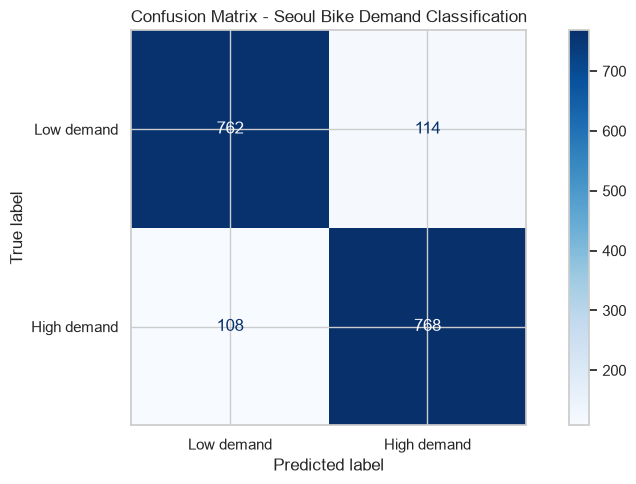

In [38]:
# Visualise the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Low demand", "High demand"])
disp.plot(cmap="Blues", values_format="d", xticks_rotation=0)
plt.title("Confusion Matrix - Seoul Bike Demand Classification")
plt.tight_layout()
plt.show()

In [39]:
# ---- Baseline comparison: a "dumb" model that always predicts the majority class ----
majority = int(y_test.value_counts().idxmax())
baseline_acc = float((y_test == majority).mean())

print("Majority class in test set:", majority)
print("Baseline (majority-only) accuracy:", round(baseline_acc, 4))
print("Logistic-regression accuracy:      ", round(acc, 4))
print("Improvement over baseline:         ", round(acc - baseline_acc, 4))

Majority class in test set: 1
Baseline (majority-only) accuracy: 0.5
Logistic-regression accuracy:       0.8733
Improvement over baseline:          0.3733


**Interpretation of the results**

The numbers above (accuracy, per-class precision/recall, and the confusion-matrix cells) show how
well the model separates High- and Low-demand hours. A good read on this data looks like:

* **Accuracy clearly above the 50% majority baseline** → the model genuinely uses the weather and
  calendar features; it is not just guessing the larger class.
* **Balanced precision and recall** for both classes → because the target is 50/50, a well-calibrated
  model should perform similarly on High and Low demand.
* **Confusion-matrix diagonal dominant** → most hours are classified correctly; the off-diagonal
  cells are the misclassified hours (mostly the borderline, near-median cases).

---

## 7. Limitations & Conclusion

**Limitations**

* **Binary simplification.** Reducing demand to High/Low with a single median threshold loses the
  magnitude of demand; a regression or multi-class model would capture more detail.
* **`Visibility` is capped.** In the source data visibility is often reported at a fixed upper
  bound (~2000 m, meaning "clear"), so it acts more like a poor-visibility flag than a true
  continuous measurement.
* **Single year, one city.** The model reflects one year in Seoul; seasonal/weather patterns may
  shift in other years or cities, so the model would need retraining on fresh data.
* **No explicit handling of extreme events.** Rare weather extremes are a small share of the data,
  so the model is less reliable on unusual days.

**Conclusion**

Using only weather and calendar features, a simple Logistic Regression classifier predicts whether
an hour in Seoul will have High or Low bike demand, evaluated with an 80/20 split
(`random_state=42`), a confusion matrix, and a majority-class baseline. The full pipeline —
cleaning, feature engineering, splitting, training and evaluation — is contained in this single,
reproducible notebook, satisfying all of the required documentation sections (A–F).
